# One channel: what the transfer matrix keeps and what it loses

The transfer matrix of a layer in which the wave is evanescent holds $e^{+\kappa d}$ and $e^{-\kappa d}$ side by side, and in finite precision the small one is lost once $\kappa d$ is large. Since $\kappa$ grows with frequency this is a statement about the product of frequency and thickness: the "$\Omega d$ problem", in the name given by Pérez-Álvarez and García-Moliner, or the "large $fd$ problem" of ultrasonics. The standard advice is to give up the transfer matrix for a scattering, stiffness or hybrid matrix.

This notebook takes the simplest setting, isotropic layers and one polarization, where the transfer matrix is $2\times2$, and asks which computed quantities are wrong, by how much, and from what thickness on. Every double-precision result is compared with the same formulas evaluated in multiprecision arithmetic, so "error" below always means distance from the exact answer of the model.

## What this notebook shows

- Past $\kappa d=\tfrac12\ln(1/\epsilon)\approx18$ (with $\epsilon$ the double-precision rounding unit) a transfer matrix is a rank-one matrix: its determinant, which should be one, has an error $\epsilon\,e^{2\kappa d}$. Its entries overflow at $\kappa d\approx710$.
- Reflection and transmission do not need the part that is lost. They come out accurate to rounding up to the overflow, from either convention, as long as no formula subtracts two large numbers. One textbook form does, the transmission by back-substitution, and it fails at $\kappa d\approx18$. Carrying a single rescaled vector instead of the matrix removes the overflow too.
- The reason is a contraction. Carried from the exit side, the physical solution is the one a barrier attracts, and errors shrink by $e^{-2\kappa d}$ per barrier. Carried from the entrance side it is the one a barrier repels, and errors grow at the same rate, so fields obtained by forward marching are wrong beyond a depth $18/\kappa$.
- There is a second, milder loss. With the layer matrix written in cosines and sines, a resonance hidden behind a barrier costs the reflection coefficient about $\log_{10}(1/\text{detuning})$ digits, although the exact value hardly depends on the detuning. Written in the layer's own two waves, the same recursion does not lose them.
- On long random stacks, Bragg mirrors with a defect, metal-dielectric stacks and an absorbing wafer, the error of the rescaled vector recursion stays within a small factor of the change that a rounding of the thicknesses produces in the exact answer, or of a few rounding units where that change is smaller.

The conclusion is that with one channel the $\Omega d$ problem can be removed by arranging the algebra, and that a recursion on a vector is as good as a scattering matrix. Notebook 02 shows that this stops being true with two or more channels.

## Conventions

Time dependence $e^{-i\omega t}$. Lengths are in free-space wavelengths, $\lambda_0=1$ and $k_0=2\pi$, so a thickness $d$ is $\Omega d/2\pi c$. Layers are stacked along $z$, the plane of incidence is $xz$, and $\beta=k_x/k_0$. Medium $a$ is on the entrance side and $b$ on the exit side. Polarizations are called s ($\mathbf E$ along $y$) and p ($\mathbf H$ along $y$); the s polarization is the one that `docs/DESIGN.md` calls TM for structures invariant along the field direction, and the names s and p are used here to avoid the clash with the usual naming for layers.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/omega_d (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd()))          # multilayer.py sits next to this notebook
import multilayer as ml
import mpmath as mp

warnings.filterwarnings("ignore", category=RuntimeWarning)   # overflow is part of the subject here
EPS = np.finfo(float).eps
KD_PREC = 0.5 * np.log(1 / EPS)                # kappa d at which exp(-2 kappa d) equals the rounding unit
KD_OVER = np.log(np.finfo(float).max)          # kappa d at which exp(kappa d) overflows
print(f"rounding unit {EPS:.3e};  (1/2) ln(1/eps) = {KD_PREC:.2f};  ln(largest double) = {KD_OVER:.2f}")

rounding unit 2.220e-16;  (1/2) ln(1/eps) = 18.02;  ln(largest double) = 709.78


## 1. The model

For one polarization the field is a scalar $u(z)$, $E_y$ for s and $H_y$ for p. With $v=u'/w$, where $w=1$ for s and $w=\varepsilon$ for p, both $u$ and $v$ are continuous at interfaces, and in a layer of permittivity $\varepsilon$

$$u''+q^2u=0,\qquad q=k_0\sqrt{\varepsilon-\beta^2},\quad\operatorname{Im}q\ge0 .$$

This is the Sturm-Liouville form in which the $\Omega d$ literature states the problem, with $u$ the field and $v$ its "linear differential form". The transfer matrix of the layer for $\psi=(u,v)$ is

$$T=\begin{pmatrix}\cos qd&\eta^{-1}\sin qd\\-\eta\sin qd&\cos qd\end{pmatrix},\qquad\eta=q/w ,$$

with $\det T=1$. A forward wave has $v=i\eta u$. With unit incidence from $a$, the fields are $\psi=(1+r,\;i\eta_a(1-r))$ at the entrance and $\psi=t\,(1,\;i\eta_b)$ at the exit.

Two conventions for the product over layers are in use. The matrix $M=T_N\cdots T_1$ carries the entrance fields to the exit; its inverse $N=T_1^{-1}\cdots T_N^{-1}$, the characteristic matrix of Born and Wolf, carries the exit fields to the entrance. In exact arithmetic they hold the same information.

The reference is the second convention evaluated with `mpmath` at enough digits to make $e^{2\kappa d}$ harmless. It is given the same double-precision inputs as the other routines, including $k_0$ as the double nearest to $2\pi$, so that it solves exactly the problem they are given.

`multilayer.py` holds several formulations of this problem. The scattering, stiffness and hybrid matrices are the subject of notebook 03; here they only serve as a first check that everything agrees on stacks without thick evanescent layers.

In [3]:
rng = np.random.default_rng(0)
worst = {}
for trial in range(30):
    layers = []
    for _ in range(rng.integers(1, 8)):
        if rng.random() < 0.8:
            layers.append((rng.uniform(1, 4) ** 2 * (1 + 1j * rng.choice([0, 0.01])), rng.uniform(0.02, 0.6)))
        else:
            layers.append((complex(-rng.uniform(2, 20), rng.uniform(0.1, 1)), rng.uniform(0.005, 0.03)))   # thin metal
    st = ml.Stack(2.25, layers, rng.choice([1.0, 2.25, 12.0 + 0.1j]))
    beta = rng.uniform(0, 1.45)
    for pol in "sp":
        ea, ls, eb = st.params(beta, pol)
        ref = ml.ref_rt(st, beta, pol)
        S = ml.S_stack(ls, ea, eb)
        rv, tm, te = ml.rt_vector(ls, ea, eb)
        res = {"transfer matrix, entrance to exit": ml.rt_from_forward(ml.T_forward(ls), ea, eb, use_det=True)[:2],
               "transfer matrix, exit to entrance": ml.rt_from_backward(ml.T_backward(ls), ea, eb),
               "rescaled vector": (rv, tm * 2.0 ** te), "scattering matrix": (S[0], S[2]),
               "stiffness matrix": ml.rt_E(ls, ea, eb), "hybrid matrix": ml.rt_H(ls, ea, eb)}
        for name, (r, t) in res.items():
            worst[name] = max(worst.get(name, 0), ml.relerr(r, ref[0]), ml.relerr(t, ref[1]))
print("largest relative error of r and t over 30 random stacks (up to 7 layers, lossy and metallic layers, both polarizations):")
for name, e in worst.items():
    check(name, e, 1e-11)

largest relative error of r and t over 30 random stacks (up to 7 layers, lossy and metallic layers, both polarizations):
PASS  transfer matrix, entrance to exit: got 6.80205e-15, target 0, |diff| 6.80e-15 <= 1e-11
PASS  transfer matrix, exit to entrance: got 6.65315e-15, target 0, |diff| 6.65e-15 <= 1e-11
PASS  rescaled vector: got 6.94898e-15, target 0, |diff| 6.95e-15 <= 1e-11
PASS  scattering matrix: got 6.99195e-15, target 0, |diff| 6.99e-15 <= 1e-11
PASS  stiffness matrix: got 1.40942e-14, target 0, |diff| 1.41e-14 <= 1e-11
PASS  hybrid matrix: got 1.41942e-13, target 0, |diff| 1.42e-13 <= 1e-11


## 2. One evanescent layer

When $q=i\kappa$ the matrix is $T=e^{\kappa d}P_++e^{-\kappa d}P_-$, where $P_\pm$ are the rank-one projectors onto the solutions that grow and decay along $z$. In double precision the second term falls below the rounding of the first when $e^{-2\kappa d}<\epsilon$. From there on the stored matrix is $e^{\kappa d}P_+$ to all its digits: a matrix of rank one, with a determinant that is the rounding error of a difference of two numbers of size $e^{2\kappa d}$.

The test structure is frustrated total reflection: glass ($n=1.5$), an air gap of thickness $d$, glass, at $60^\circ$, s polarization. The exact transmission is of order $e^{-\kappa d}$. Six ways of getting numbers out of the transfer matrix are compared.

- $|\det M-1|$.
- $t$ from $M$ by back-substitution, $t=A(1+r)+i\eta_aB(1-r)$ with $M=\begin{pmatrix}A&B\\C&D\end{pmatrix}$. This is what solving the two boundary equations in the natural order gives. It is the one-channel case of the Schur complement $K_{11}-K_{12}K_{22}^{-1}K_{21}$ that the entrance-to-exit convention needs with several channels.
- $t$ from $M$ with the determinant put in by hand, $t=2i\eta_a/(i\eta_aD+\eta_a\eta_bB+i\eta_bA-C)$.
- $r$ from $M$.
- $r$ and $t$ from $N$, which only uses $N$ applied to the outgoing vector $(1,i\eta_b)$.
- $r$ and $t$ from that one vector carried through the layers and rescaled by a power of two after each, with $t$ returned as a mantissa and a binary exponent, so that nothing can overflow or underflow.

gap: beta = 1.2990, kappa = 5.2097 per wavelength; kappa d = 18.02 at d = 3.46, 709.8 at d = 136.2 wavelengths


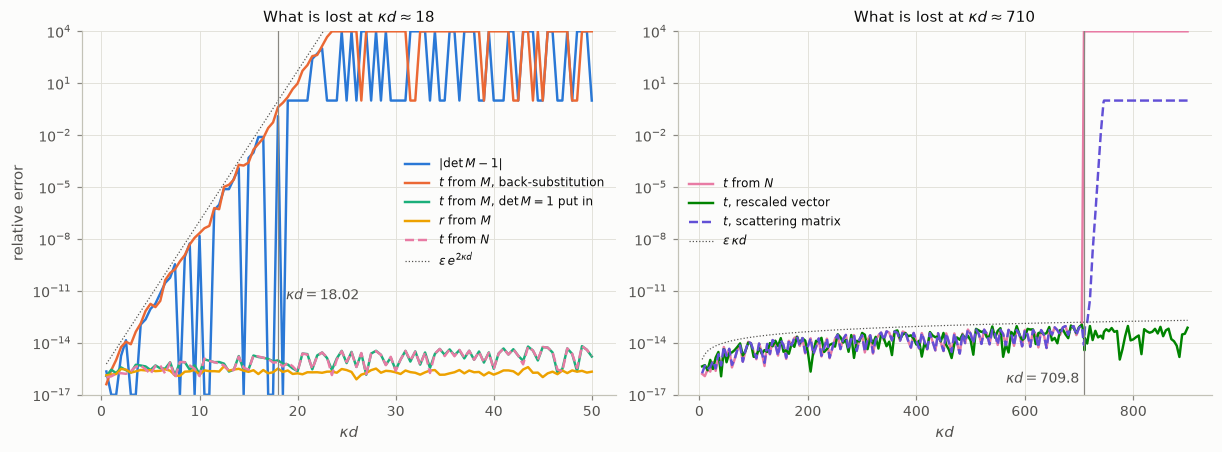

PASS  exponent of the determinant error, d ln|det M - 1| / d(kappa d): got 1.9997, target 2, |diff| 2.97e-04 <= 1e-01
PASS  kappa d where the back-substituted t first has a relative error above 0.1: got 18, target 18.0218, |diff| 2.18e-02 <= 2e+00
PASS  largest error of r from M and of r, t from N, kappa d < 700: got 9.28211e-14, target 0, |diff| 9.28e-14 <= 1e-12
PASS  largest error of t from M with det M = 1 put in, kappa d < 700: got 9.28151e-14, target 0, |diff| 9.28e-14 <= 1e-12
PASS  kappa d at which r, t from N stop being finite numbers: got 709, target 709.783, |diff| 7.83e-01 <= 2e+00
PASS  largest error of r and t from the rescaled vector, kappa d up to 900: got 1.12021e-13, target 0, |diff| 1.12e-13 <= 1e-12
PASS  largest error of r from the scattering matrix, kappa d up to 900: got 1.65943e-16, target 0, |diff| 1.66e-16 <= 1e-13
t from the scattering matrix underflows to zero from kappa d = 745 on: the exact |t| is below the smallest double.


In [4]:
beta_g = 1.5 * np.sin(np.radians(60))
kap = abs(ml.kz(1.0, beta_g).imag)             # decay rate in the gap, per wavelength
print(f"gap: beta = {beta_g:.4f}, kappa = {kap:.4f} per wavelength; kappa d = 18.02 at d = {KD_PREC / kap:.2f}, 709.8 at d = {KD_OVER / kap:.1f} wavelengths")


def gap_errors(kd):
    st = ml.Stack(2.25, [(1.0, kd / kap)], 2.25)
    ea, ls, eb = st.params(beta_g, "s")
    ref = ml.ref_rt(st, beta_g, "s")
    M = ml.T_forward(ls)
    sub, det = ml.rt_from_forward(M, ea, eb), ml.rt_from_forward(M, ea, eb, use_det=True)
    bwd = ml.rt_from_backward(ml.T_backward(ls), ea, eb)
    rv, tm, te = ml.rt_vector(ls, ea, eb)
    S = ml.S_stack(ls, ea, eb)
    d = abs(M[0] * M[3] - M[1] * M[2] - 1)
    return [d if np.isfinite(d) else np.inf, ml.relerr(sub[1], ref[1]), ml.relerr(det[1], ref[1]), ml.relerr(det[0], ref[0]),
            ml.relerr(bwd[0], ref[0]), ml.relerr(bwd[1], ref[1]), ml.relerr(rv, ref[0]), ml.relerr_scaled(tm, te, ref[1]),
            ml.relerr(S[0], ref[0]), ml.relerr(S[2], ref[1])]


kd1 = np.linspace(0.5, 50, 100)
kd2 = np.unique(np.concatenate([np.linspace(5, 900, 180), [700, 705, 709, 711, 715, 740, 744, 746, 750]]))
E1 = np.array([gap_errors(k) for k in kd1])
E2 = np.array([gap_errors(k) for k in kd2])

FLOOR = 1e-17
clip = lambda e: np.clip(np.where(np.isfinite(e), e, 1e30), FLOOR, 1e4)
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax = axes[0]
ax.semilogy(kd1, clip(E1[:, 0]), color=CAT[0], label=r"$|\det M-1|$")
ax.semilogy(kd1, clip(E1[:, 1]), color=CAT[1], label=r"$t$ from $M$, back-substitution")
ax.semilogy(kd1, clip(E1[:, 2]), color=CAT[2], label=r"$t$ from $M$, $\det M=1$ put in")
ax.semilogy(kd1, clip(E1[:, 3]), color=CAT[3], label=r"$r$ from $M$")
ax.semilogy(kd1, clip(E1[:, 5]), color=CAT[4], ls="--", label=r"$t$ from $N$")
ax.semilogy(kd1, EPS * np.exp(2 * kd1), color=INK2, lw=0.8, ls=":", label=r"$\epsilon\,e^{2\kappa d}$")
ax.axvline(KD_PREC, color=MUTED, lw=0.8)
ax.text(KD_PREC + 0.8, 2e-12, r"$\kappa d=18.02$", color=INK2, fontsize=9, va="bottom")
ax.set(xlabel=r"$\kappa d$", ylabel="relative error", ylim=(1e-17, 1e4), title="What is lost at $\\kappa d\\approx18$")
ax.legend(loc="center right", fontsize=8)
ax = axes[1]
ax.semilogy(kd2, clip(E2[:, 5]), color=CAT[4], label=r"$t$ from $N$")
ax.semilogy(kd2, clip(E2[:, 7]), color=CAT[5], label=r"$t$, rescaled vector")
ax.semilogy(kd2, clip(E2[:, 9]), color=CAT[6], ls="--", label=r"$t$, scattering matrix")
ax.semilogy(kd2, EPS * kd2, color=INK2, lw=0.8, ls=":", label=r"$\epsilon\,\kappa d$")
ax.axvline(KD_OVER, color=MUTED, lw=0.8)
ax.text(KD_OVER - 8, 3e-17, r"$\kappa d=709.8$", color=INK2, fontsize=9, va="bottom", ha="right")
ax.set(xlabel=r"$\kappa d$", ylim=(1e-17, 1e4), title="What is lost at $\\kappa d\\approx710$")
ax.legend(loc="center left", fontsize=8)
plt.show()

sel = (E1[:, 0] > 1e-12) & (E1[:, 0] < 1e-3)
slope = np.polyfit(kd1[sel], np.log(E1[sel, 0]), 1)[0]
check("exponent of the determinant error, d ln|det M - 1| / d(kappa d)", slope, 0.1, 2.0)
check("kappa d where the back-substituted t first has a relative error above 0.1", kd1[np.argmax(E1[:, 1] > 0.1)], 1.5, KD_PREC)
ok = kd2 < 700
check("largest error of r from M and of r, t from N, kappa d < 700", max(E2[ok, 3].max(), E2[ok, 4].max(), E2[ok, 5].max()), 1e-12)
check("largest error of t from M with det M = 1 put in, kappa d < 700", E2[ok, 2].max(), 1e-12)
first_bad = kd2[np.argmax(~np.isfinite(E2[:, 5]))]
check("kappa d at which r, t from N stop being finite numbers", first_bad, 2.0, KD_OVER)
check("largest error of r and t from the rescaled vector, kappa d up to 900", max(E2[:, 6].max(), E2[:, 7].max()), 1e-12)
check("largest error of r from the scattering matrix, kappa d up to 900", E2[:, 8].max(), 1e-13)
print(f"t from the scattering matrix underflows to zero from kappa d = {kd2[np.argmax(E2[:, 9] > 0.5)]:.0f} on: the exact |t| is below the smallest double.")

The left panel separates two kinds of quantity. The determinant and the back-substituted transmission follow $\epsilon\,e^{2\kappa d}$ and are meaningless past the vertical line. Everything else stays at rounding level, including $t$ from the same matrix $M$ once the determinant is not asked of the numbers. The right panel shows the other limit: a formula that stores $e^{\kappa d}$ ends in `inf` at $\kappa d=709.8$, the rescaled vector does not, and the slow rise proportional to $\epsilon\,\kappa d$ is shared by all methods because it is the rounding of the product $\kappa d$ itself inside the exponential.

So for one layer the loss is real but avoidable, and what avoids it is algebra and not a different matrix: $r$, $t$, and the reflection and transmission from the other side are ratios in which the rank-one part $e^{\kappa d}P_+$ cancels as a common factor. No subtraction of large numbers is needed, provided $\det M=1$ is used as a fact and not computed.

## 3. Why the exit-to-entrance direction is the stable one

A solution is a vector $\psi$, but $r$ only depends on its direction, a point of the projective line, for which the admittance $Y=v/u$ is a coordinate. A layer acts on $Y$ by a Möbius map with two fixed points, the admittances $\pm i\eta$ of the two waves of the layer. Carried across an evanescent layer in either direction, every direction but one is pulled toward the fixed point of the wave that grows in the direction of travel, at the rate $e^{-2\kappa d}$; the exception is the other fixed point, which repels at the rate $e^{+2\kappa d}$.

Going from the exit toward the entrance, the physical solution is the wave that grows in the direction of travel (it decays toward the exit), so it sits at the attracting fixed point. A rounding error made on the way is a small change of direction, and the barrier shrinks it. Going from the entrance toward the exit, the physical solution sits at the repelling fixed point, and a deviation $\delta$ from it becomes $\delta\,e^{2\kappa d}$.

The one-vector recursion from the exit side is therefore the Parratt recursion for the reflection coefficient written in homogeneous coordinates: it carries the direction, and the length only matters for $t$.

In [5]:
print("a gap of thickness d, and a direction changed by delta = 1e-9; change at the far side divided by delta:")
print("  kappa d    exit -> entrance, generic direction    exp(-2 kappa d)    entrance -> exit, next to the decaying wave    exp(+2 kappa d)")
delta = 1e-9
ok_c, ok_e = [], []
for kd in (2.0, 4.0, 6.0, 8.0):
    with mp.workdps(60):
        q = mp.mpc(0, kap); d = mp.mpf(kd) / kap
        c, s = mp.cos(q * d), mp.sin(q * d)

        def carry(Y, back):                     # admittance v/u carried through the gap
            u, v = mp.mpf(1), Y
            if back:
                u, v = c * u - s / q * v, q * s * u + c * v
            else:
                u, v = c * u + s / q * v, -q * s * u + c * v
            return v / u
        Y0 = mp.mpc(0.3, 1.1)                   # a generic direction at the exit face
        con = abs(carry(Y0 * (1 + delta), True) - carry(Y0, True)) / abs(carry(Y0, True)) / delta
        Yd = mp.mpc(0, 1) * q                   # the wave that decays along z: v = i q u
        exp_ = abs(carry(Yd * (1 + delta), False) - Yd) / abs(Yd) / delta
    print(f"  {kd:7.1f}    {float(con):34.3e}    {np.exp(-2 * kd):15.3e}    {float(exp_):43.3e}    {np.exp(2 * kd):15.3e}")
    ok_c.append(np.log(float(con)) + 2 * kd); ok_e.append(np.log(float(exp_)) - 2 * kd)
check("spread of ln(contraction) + 2 kappa d over the four rows (a constant prefactor)", max(ok_c) - min(ok_c), 0.01)
check("spread of ln(expansion) - 2 kappa d over the four rows", max(ok_e) - min(ok_e), 0.05)

a gap of thickness d, and a direction changed by delta = 1e-9; change at the far side divided by delta:
  kappa d    exit -> entrance, generic direction    exp(-2 kappa d)    entrance -> exit, next to the decaying wave    exp(+2 kappa d)
      2.0                             1.720e-02          1.832e-02                                      5.460e+01          5.460e+01
      4.0                             3.149e-04          3.355e-04                                      2.981e+03          2.981e+03
      6.0                             5.767e-06          6.144e-06                                      1.628e+05          1.628e+05
      8.0                             1.056e-07          1.125e-07                                      8.926e+06          8.886e+06
PASS  spread of ln(contraction) + 2 kappa d over the four rows (a constant prefactor): got 0.000280773, target 0, |diff| 2.81e-04 <= 1e-02
PASS  spread of ln(expansion) - 2 kappa d over the four rows: got 0.00445293, target 0, |di

## 4. Fields inside the stack

The field profile is where the direction of marching cannot be chosen away by algebra. Starting at the entrance with the computed $r$, the vector $(1+r,\;i\eta_a(1-r))$ has a relative error $\epsilon$, which is a component of size $\epsilon$ along the solution that grows with $z$. The true field in a barrier decays, the error grows, and they meet at a depth $z^*=\tfrac12\ln(1/\epsilon)/\kappa$. Starting at the exit with the computed $t$ and marching back, the true field is the growing one and the error decays.

The structure is glass, an air gap, a glass film, a second air gap, glass, again at $60^\circ$. Three reconstructions are compared with the reference: forward marching, backward marching, and a reconstruction from the reflection coefficients seen from inside each layer (forward amplitudes kept at entrance faces, backward amplitudes at exit faces, so that every exponential decays).

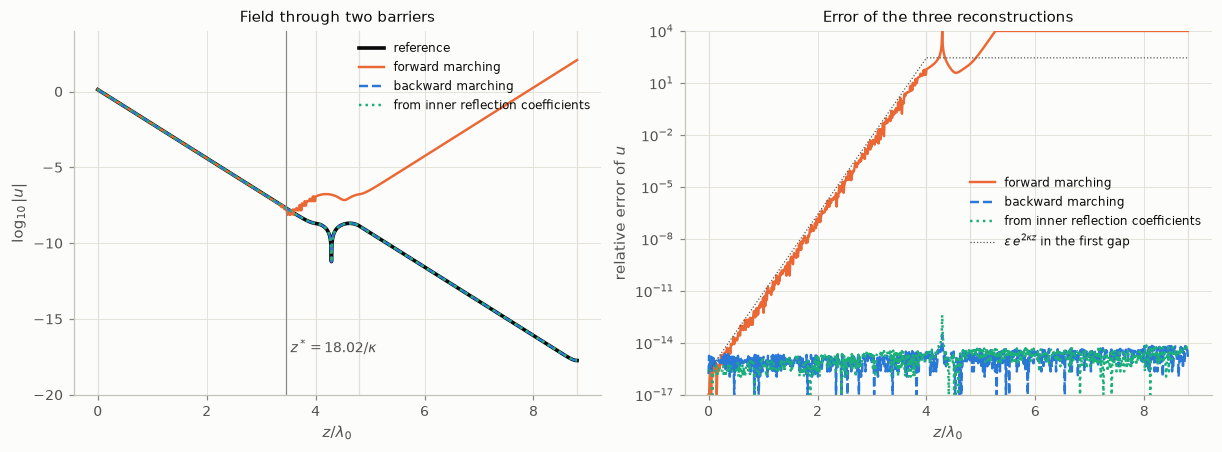

PASS  depth at which forward marching first has a relative error above 0.1 (wavelengths): got 3.33, target 3.45926, |diff| 1.29e-01 <= 4e-01
PASS  largest relative error of backward marching: got 2.9263e-14, target 0, |diff| 2.93e-14 <= 1e-10
PASS  largest relative error of the reconstruction from inner reflection coefficients: got 4.02843e-13, target 0, |diff| 4.03e-13 <= 1e-10


In [6]:
gap = 4.0
st_f = ml.Stack(2.25, [(1.0, gap), (2.25, 0.8), (1.0, gap)], 2.25)
z = np.linspace(0, st_f.interfaces()[-1], 881)
la, ph = ml.ref_field(st_f, beta_g, "s", z)
u_ref_log = la
fields = {"forward marching": ml.field_T(st_f, beta_g, "s", z, "forward"),
          "backward marching": ml.field_T(st_f, beta_g, "s", z, "backward"),
          "from inner reflection coefficients": ml.field_S(st_f, beta_g, "s", z)}


def field_err(u):
    """relative error against the reference, computed from log-magnitude and phase to survive underflow"""
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.abs(u) / 10.0 ** la * np.exp(1j * (np.angle(u) - ph))
    return np.abs(ratio - 1)


fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax = axes[0]
ax.plot(z, la, color=INK, lw=2.4, label="reference")
for (name, u), c, ls in zip(fields.items(), (CAT[1], CAT[0], CAT[2]), ("-", "--", ":")):
    with np.errstate(divide="ignore"):
        ax.plot(z, np.log10(np.abs(u)), color=c, ls=ls, label=name)
for zi in st_f.interfaces():
    ax.axvline(zi, color=GRID, lw=0.8, zorder=0)
zstar = KD_PREC / kap
ax.axvline(zstar, color=MUTED, lw=0.8)
ax.text(zstar + 0.08, -17.2, r"$z^*=18.02/\kappa$", color=INK2, fontsize=9)
ax.set(xlabel=r"$z/\lambda_0$", ylabel=r"$\log_{10}|u|$", ylim=(-20, 4), title="Field through two barriers")
ax.legend(loc="upper right", fontsize=8)
ax = axes[1]
for (name, u), c, ls in zip(fields.items(), (CAT[1], CAT[0], CAT[2]), ("-", "--", ":")):
    ax.semilogy(z, np.clip(field_err(u), FLOOR, 1e4), color=c, ls=ls, label=name)
ax.semilogy(z, np.minimum(EPS * np.exp(2 * kap * np.minimum(z, gap)), 1e4), color=INK2, lw=0.8, ls=":", label=r"$\epsilon\,e^{2\kappa z}$ in the first gap")
for zi in st_f.interfaces():
    ax.axvline(zi, color=GRID, lw=0.8, zorder=0)
ax.set(xlabel=r"$z/\lambda_0$", ylabel="relative error of $u$", ylim=(1e-17, 1e4), title="Error of the three reconstructions")
ax.legend(loc="center right", fontsize=8)
plt.show()

e_f, e_b, e_s = (field_err(u) for u in fields.values())
check("depth at which forward marching first has a relative error above 0.1 (wavelengths)", z[np.argmax(e_f > 0.1)], 0.4, zstar)
check("largest relative error of backward marching", e_b.max(), 1e-10)
check("largest relative error of the reconstruction from inner reflection coefficients", e_s.max(), 1e-10)

## 5. A hidden resonance: where the form of the layer matrix matters

The contraction argument has one exception: the direction that a barrier does not attract, which is the solution that decays toward the entrance. A vector arrives at a barrier along it when the part of the stack behind the barrier is at resonance. Take the same double barrier and vary the thickness of the film near a resonance. Away from the exact resonance by a relative detuning $\delta$, the vector entering the first barrier has a fraction of order $\delta$ along the growing solution and the rest along the decaying one.

With the layer written as a matrix of cosines and sines, each component of the outgoing vector is then formed as a difference, $\cosh(\kappa d)\,u-\kappa^{-1}\sinh(\kappa d)\,v$, of two terms that cancel to a relative $\delta$, and each component gets its own rounding error of relative size $\epsilon/\delta$. The direction is perturbed by that much, and $r$ with it. The exact $r$ meanwhile hardly depends on $\delta$, because the resonance is hidden behind a barrier of transmission $e^{-\kappa d}$.

The cancellation is real but it can be done once instead of twice. If the vector is first split into the two waves of the layer, each multiplied by its own exponential, and the fields put together again, the small amplitude is computed once, with a relative error $\epsilon/\delta$ that only affects the length of the vector, and the direction is exact. This is the same recursion in exact arithmetic (`rt_vector(..., modal=True)`).

resonant film thickness 1.021256186865800518  (imaginary part 4.4e-98)
PASS  exact transmission at the resonant thickness: got 1, target 1, |diff| 0.00e+00 <= 1e-12


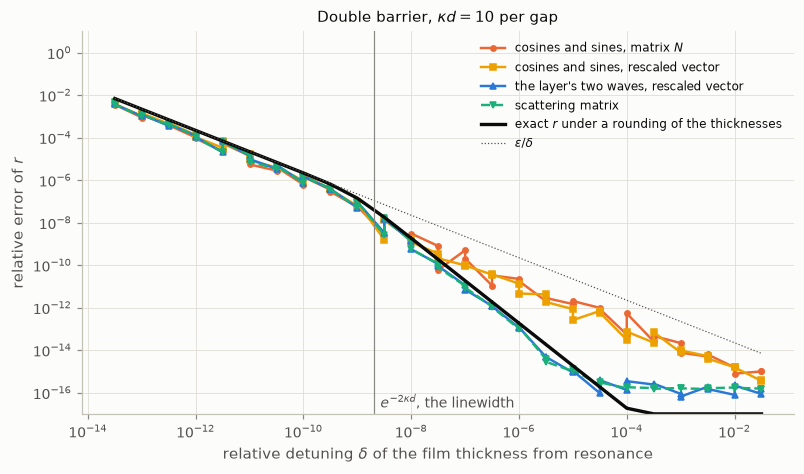

PASS  slope of the error of the cosine-sine recursion against detuning, 1e-6 to 1e-2: got -0.904847, target -1, |diff| 9.52e-02 <= 2e-01
PASS  largest error of the two-wave recursion over max(intrinsic, 2e-16), all detunings: got 1.92774, target 0, |diff| 1.93e+00 <= 1e+01
PASS  largest error of the scattering matrix over max(intrinsic, 2e-16), all detunings: got 1.52494, target 0, |diff| 1.52e+00 <= 1e+01
detuning 1e-6 to 1e-3: the cosine-sine recursion has 353 times the error of the two-wave recursion (geometric mean)
inside the linewidth: errors 5.0e-08 to 4.7e-03 for all four, intrinsic change 1.4e-07 to 6.9e-03
PASS  inside the linewidth, largest error of any of the four over the intrinsic change: got 0.989248, target 0, |diff| 9.89e-01 <= 1e+01


In [7]:
kd_gap = 10.0
g = kd_gap / kap
dbl = lambda dw: ml.Stack(2.25, [(1.0, g), (2.25, dw), (1.0, g)], 2.25)

# coarse location of a resonance from the transmission, then its exact position as the zero of the
# numerator of r (an entire function of the film thickness) in multiprecision
dws = np.linspace(0.5, 1.2, 20001)
ea, ls, eb = dbl(dws).params(beta_g, "s")
d_coarse = dws[np.argmax(abs(ml.S_stack(ls, ea, eb)[2]))]
DPS = 80


def numerator(dw):
    (A, B, C, D), ea_, eb_ = ml.ref_matrix(dbl(dw), beta_g, "s", DPS)
    j = mp.mpc(0, 1)
    return (A + j * eb_ * B) - (C + j * eb_ * D) / (j * ea_)


with mp.workdps(DPS):
    d_res = mp.findroot(numerator, (mp.mpf(d_coarse), mp.mpf(d_coarse) + mp.mpf("1e-6")), solver="secant", tol=mp.mpf(10) ** (-60))
    print(f"resonant film thickness {mp.nstr(mp.re(d_res), 20)}  (imaginary part {float(abs(mp.im(d_res))):.1e})")
    d_res = mp.re(d_res)
    T_res = float(abs(ml.ref_rt(dbl(d_res), beta_g, "s", DPS)[1]) ** 2)
check("exact transmission at the resonant thickness", T_res, 1e-12, 1.0)

rng = np.random.default_rng(3)
rows = []
for expo in np.arange(-13.5, -1.4, 0.5):
    for sign in (1, -1):
        with mp.workdps(DPS):
            dw = float(d_res * (1 + sign * mp.mpf(10) ** expo))
            det_actual = float(abs(mp.mpf(dw) - d_res) / d_res)
        st = dbl(dw)
        ea, ls, eb = st.params(beta_g, "s")
        ref = ml.ref_rt(st, beta_g, "s", DPS)
        intrinsic = 0.0                               # change of the exact r when every thickness moves by one rounding unit
        for _ in range(4):
            st2 = ml.Stack(2.25, [(e, d * (1 + EPS * rng.choice([-1, 1]))) for e, d in st.layers], 2.25)
            with mp.workdps(DPS):
                intrinsic = max(intrinsic, float(abs(ml.ref_rt(st2, beta_g, "s", DPS)[0] - ref[0]) / abs(ref[0])))
        rows.append([det_actual, ml.relerr(ml.rt_from_backward(ml.T_backward(ls), ea, eb)[0], ref[0]),
                     ml.relerr(ml.rt_vector(ls, ea, eb)[0], ref[0]), ml.relerr(ml.rt_vector(ls, ea, eb, modal=True)[0], ref[0]),
                     ml.relerr(ml.S_stack(ls, ea, eb)[0], ref[0]), intrinsic])
rows = np.array(sorted(rows, key=lambda x: x[0]))

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.loglog(rows[:, 0], np.clip(rows[:, 1], FLOOR, None), "o-", ms=3.5, color=CAT[1], label="cosines and sines, matrix $N$")
ax.loglog(rows[:, 0], np.clip(rows[:, 2], FLOOR, None), "s-", ms=3.5, color=CAT[3], label="cosines and sines, rescaled vector")
ax.loglog(rows[:, 0], np.clip(rows[:, 3], FLOOR, None), "^-", ms=3.5, color=CAT[0], label="the layer's two waves, rescaled vector")
ax.loglog(rows[:, 0], np.clip(rows[:, 4], FLOOR, None), "v--", ms=3.5, color=CAT[2], label="scattering matrix")
ax.loglog(rows[:, 0], np.clip(rows[:, 5], FLOOR, None), color=INK, lw=2.2, label="exact $r$ under a rounding of the thicknesses")
ax.loglog(rows[:, 0], EPS / rows[:, 0], color=INK2, lw=0.8, ls=":", label=r"$\epsilon/\delta$")
ax.axvline(np.exp(-2 * kd_gap), color=MUTED, lw=0.8)
ax.text(np.exp(-2 * kd_gap) * 1.3, 2e-17, r"$e^{-2\kappa d}$, the linewidth", color=INK2, fontsize=9)
ax.set(xlabel=r"relative detuning $\delta$ of the film thickness from resonance", ylabel="relative error of $r$", ylim=(1e-17, 1e1),
       title=r"Double barrier, $\kappa d=10$ per gap")
ax.legend(fontsize=8, loc="upper right")
plt.show()

off = (rows[:, 0] > 1e-6) & (rows[:, 0] < 1e-2)
sl = np.polyfit(np.log(rows[off, 0]), np.log(rows[off, 2]), 1)[0]
check("slope of the error of the cosine-sine recursion against detuning, 1e-6 to 1e-2", sl, 0.25, -1.0)
floor = np.maximum(rows[:, 5], 2e-16)
check("largest error of the two-wave recursion over max(intrinsic, 2e-16), all detunings", (rows[:, 3] / floor).max(), 10.0)
check("largest error of the scattering matrix over max(intrinsic, 2e-16), all detunings", (rows[:, 4] / floor).max(), 10.0)
mid = (rows[:, 0] > 1e-6) & (rows[:, 0] < 1e-3)
gm = np.exp(np.mean(np.log(rows[mid, 2] / rows[mid, 3])))
print(f"detuning 1e-6 to 1e-3: the cosine-sine recursion has {gm:.0f} times the error of the two-wave recursion (geometric mean)")
assert gm > 30
near = rows[:, 0] < np.exp(-2 * kd_gap)
print(f"inside the linewidth: errors {rows[near, 1:5].min():.1e} to {rows[near, 1:5].max():.1e} for all four, intrinsic change {rows[near, 5].min():.1e} to {rows[near, 5].max():.1e}")
check("inside the linewidth, largest error of any of the four over the intrinsic change", (rows[near, 1:5].max(axis=1) / rows[near, 5]).max(), 10.0)

Inside the linewidth all four curves lie on the black one: there the problem itself is ill conditioned, a rounding of the thicknesses changes the exact $r$ by that much, and no method can do better in double precision. Outside it, the two recursions that use cosines and sines follow $\epsilon/\delta$ while the exact answer is far less sensitive. The recursion in the layer's two waves and the scattering matrix follow the exact sensitivity down to rounding level.

How much this matters depends on how sharp the hidden resonance can be. Here the film is lossless and the detuning can be made as small as the linewidth $e^{-2\kappa d}$. With absorption in the film the fraction along the growing solution cannot fall below the absorption per pass, and the loss is bounded by that many digits.

## 6. Stress tests

The same comparison on structures chosen to be hard: random stacks of up to 800 layers in which the air layers are evanescent, Bragg mirrors with a cavity (no layer is evanescent there, the decay comes from interference, and the transfer matrix still grows like $1/|t|$), metal-dielectric stacks in p polarization, a surface-plasmon geometry, and an absorbing wafer several hundred decay lengths thick.

For each, the table gives the error of $r$ and of $t$ from the matrix $N$, from the rescaled vector in the two-wave form, and from the scattering matrix, next to the intrinsic sensitivity: the largest change of the exact value when every thickness is changed by one rounding unit, up or down at random. An entry "ovf" means the result was not a finite number, and "unf" that the exact $|t|$ is below the smallest normal double, so that a routine returning $t$ as one number cannot hold it.

In [8]:
rng = np.random.default_rng(1)


def intrinsic_sensitivity(st, beta, pol, ref, ntry=3):
    out = np.zeros(2)
    dps = ml.ref_digits(st, beta)
    for _ in range(ntry):
        st2 = ml.Stack(st.eps_a, [(e, d * (1 + EPS * rng.choice([-1, 1]))) for e, d in st.layers], st.eps_b)
        r2 = ml.ref_rt(st2, beta, pol, dps)
        with mp.workdps(60):
            out = np.maximum(out, [float(abs(r2[i] - ref[i]) / abs(ref[i])) for i in (0, 1)])
    return out


fmt = lambda e: "   ovf  " if np.isinf(e) else ("   unf  " if np.isnan(e) else f"{e:8.1e}")
table = []


def report(name, st, beta, pol="s"):
    ea, ls, eb = st.params(beta, pol)
    ref = ml.ref_rt(st, beta, pol)
    b = ml.rt_from_backward(ml.T_backward(ls), ea, eb)
    S = ml.S_stack(ls, ea, eb)
    rv, tm, te = ml.rt_vector(ls, ea, eb, modal=True)
    sens = intrinsic_sensitivity(st, beta, pol, ref)
    growth = sum(abs(q.imag) * d for q, _, d in ls)
    logt = float(mp.log10(abs(ref[1])))
    tS = ml.relerr(S[2], ref[1]) if logt > -307 else np.nan          # below the smallest normal double the exact t cannot be stored
    row = dict(name=name, growth=growth, logt=logt, rN=ml.relerr(b[0], ref[0]), rV=ml.relerr(rv, ref[0]),
               rS=ml.relerr(S[0], ref[0]), rI=sens[0], tN=ml.relerr(b[1], ref[1]), tV=ml.relerr_scaled(tm, te, ref[1]), tS=tS, tI=sens[1])
    table.append(row)
    print(f"{name:34s} {growth:7.1f} {row['logt']:8.1f} | {fmt(row['rN'])} {fmt(row['rV'])} {fmt(row['rS'])} {fmt(row['rI'])} | "
          f"{fmt(row['tN'])} {fmt(row['tV'])} {fmt(row['tS'])} {fmt(row['tI'])}")


print(f"{'structure':34s} {'sum kd':>7s} {'lg|t|':>8s} | {'r: N':>8s} {'vector':>8s} {'S':>8s} {'intr.':>8s} | {'t: N':>8s} {'vector':>8s} {'S':>8s} {'intr.':>8s}")
for L in (200, 800, 3000):
    layers = [(rng.choice([1.0, 2.25, 12.25]), rng.uniform(0.05, 0.5)) for _ in range(L)]
    report(f"random, {L} layers, s", ml.Stack(2.25, layers, 2.25), 1.2)
    report(f"random, {L} layers, p", ml.Stack(2.25, layers, 2.25), 1.2, "p")
nH, nL = 2.3, 1.45
pair = [(nH ** 2, 0.25 / nH), (nL ** 2, 0.25 / nL)]
for Np in (60, 150, 1200):
    report(f"Bragg {Np} + cavity + {Np} pairs", ml.Stack(1.0, pair * Np + [(nL ** 2, 0.37)] + pair[::-1] * Np, 1.0), 0.0)
ag = -18.3 + 0.5j
report("glass | Ag 0.1 | SiO2 0.3 | Ag 0.1", ml.Stack(2.25, [(ag, 0.1), (2.1, 0.3), (ag, 0.1)], 1.0), 0.3, "p")
report("glass | Ag 2 | SiO2 0.3 | Ag 2", ml.Stack(2.25, [(ag, 2.0), (2.1, 0.3), (ag, 2.0)], 1.0), 0.3, "p")
report("5 x (Ag 1 | SiO2 0.37)", ml.Stack(2.25, [(ag, 1.0), (2.1, 0.37)] * 5, 1.0), 0.9, "p")
report("glass | Ag 0.08 | air, plasmon angle", ml.Stack(2.25, [(ag, 0.08)], 1.0), 1.04, "p")
report("SiO2 0.2 | absorbing wafer 1000", ml.Stack(1.0, [(2.1, 0.2), (18.5 + 0.6j, 1000.0)], 1.0), 0.5, "p")
report("SiO2 0.2 | absorbing wafer 2000", ml.Stack(1.0, [(2.1, 0.2), (18.5 + 0.6j, 2000.0)], 1.0), 0.5, "p")

worst_r = max(row["rV"] / max(row["rI"], 1e-15) for row in table)
worst_t = max(row["tV"] / max(row["tI"], 1e-14) for row in table)
print()
check("largest ratio of the vector recursion's error of r to max(intrinsic, 1e-15)", worst_r, 30.0)
check("largest ratio of the vector recursion's error of t to max(intrinsic, 1e-14)", worst_t, 30.0)
check("largest error of r from the scattering matrix over max(intrinsic, 1e-15)", max(row["rS"] / max(row["rI"], 1e-15) for row in table), 30.0)
n_ovf = sum(np.isinf(row["rN"]) for row in table)
print(f"rows in which the matrix N overflowed: {n_ovf};  rows in which t from the scattering matrix underflowed: {sum(np.isnan(row['tS']) for row in table)}")
assert n_ovf >= 2

structure                           sum kd    lg|t| |     r: N   vector        S    intr. |     t: N   vector        S    intr.


random, 200 layers, s                 84.9    -37.3 |  4.8e-15  7.6e-16  7.6e-16  1.7e-15 |  2.5e-15  5.6e-15  1.2e-14  1.2e-13
random, 200 layers, p                 84.9    -27.7 |  1.4e-15  1.1e-15  1.3e-15  1.7e-15 |  1.3e-14  1.0e-14  8.5e-15  6.1e-14


random, 800 layers, s                282.5   -119.1 |  5.4e-14  6.7e-16  8.1e-16  2.7e-15 |  5.0e-13  7.1e-13  6.6e-13  3.0e-13


random, 800 layers, p                282.5    -95.0 |  1.6e-15  2.1e-15  1.7e-15  5.3e-15 |  5.8e-15  3.3e-15  1.7e-14  1.4e-13


random, 3000 layers, s              1081.4   -456.4 |    ovf    7.1e-16  6.3e-16  8.3e-16 |    ovf    2.3e-14    unf    1.3e-12


random, 3000 layers, p              1081.4   -352.9 |    ovf    1.3e-15  8.0e-16  1.6e-15 |    ovf    3.9e-13    unf    1.4e-13
Bragg 60 + cavity + 60 pairs           0.0    -23.3 |  1.9e-16  2.4e-16  1.9e-16  3.5e-16 |  8.3e-15  8.2e-15  1.2e-14  6.5e-15
Bragg 150 + cavity + 150 pairs         0.0    -59.3 |  1.5e-16  1.1e-16  1.9e-16  5.6e-16 |  1.8e-14  1.9e-14  3.2e-14  1.9e-15


Bragg 1200 + cavity + 1200 pairs       0.0   -480.1 |    ovf    1.2e-16  1.9e-16  5.3e-16 |    ovf    1.4e-13    unf    1.1e-15
glass | Ag 0.1 | SiO2 0.3 | Ag 0.1     5.4     -1.9 |  1.8e-16  3.0e-16  3.0e-16  6.3e-17 |  3.3e-15  3.3e-15  2.7e-15  3.9e-15
glass | Ag 2 | SiO2 0.3 | Ag 2       107.8    -46.4 |  1.8e-16  2.1e-16  2.1e-16  1.2e-60 |  9.1e-15  6.2e-15  9.5e-15  2.6e-14
5 x (Ag 1 | SiO2 0.37)               137.3    -58.0 |  4.7e-16  2.1e-16  1.2e-16  4.3e-38 |  1.2e-14  3.5e-15  1.3e-14  2.8e-14
glass | Ag 0.08 | air, plasmon angle     2.2      0.3 |  1.4e-15  2.6e-16  3.0e-16  2.0e-16 |  8.6e-16  3.0e-16  1.6e-16  4.4e-16
SiO2 0.2 | absorbing wafer 1000      441.2   -191.7 |  4.2e-16  4.6e-16  1.8e-16  1.4e-15 |  5.2e-13  5.2e-13  5.2e-13  6.1e-12
SiO2 0.2 | absorbing wafer 2000      882.4   -383.3 |    ovf    4.6e-16  1.8e-16  1.4e-15 |    ovf    1.0e-12    unf    1.2e-11

PASS  largest ratio of the vector recursion's error of r to max(intrinsic, 1e-15): got 0.829767, targ

## 7. Where the two thresholds fall

The thicknesses at which $\kappa d$ reaches $18.02$, where the determinant, the back-substituted transmission and forward-marched fields are lost, and $709.8$, where a stored $e^{\kappa d}$ overflows. The optical constants are round values of the right size for the material and wavelength named, meant for orders of magnitude only. The last rows are not materials but the evanescent waves of large $\beta$ that a near-field calculation integrates over (emission of a dipole near a stack, radiative heat transfer between close bodies), and the diffraction orders of a grating of period $\Lambda=\lambda_0$, where order $m$ has $\beta\approx m$.

In [9]:
cases = [("air gap between glass prisms, 60 degrees", 1.0, beta_g, 0.633),
         ("silver at 633 nm, normal incidence", -18.3 + 0.5j, 0.0, 0.633),
         ("gold at 1550 nm, normal incidence", -115 + 11j, 0.0, 1.55),
         ("silicon at 500 nm, normal incidence", 18.5 + 0.6j, 0.0, 0.5),
         ("silicon at 400 nm, normal incidence", 30.9 + 4.3j, 0.0, 0.4),
         ("vacuum, beta = 3", 1.0, 3.0, None), ("vacuum, beta = 10", 1.0, 10.0, None), ("vacuum, beta = 50", 1.0, 50.0, None)]
print(f"{'layer':42s} {'kappa (1/wavelength)':>21s} {'d at 18.02':>12s} {'d at 709.8':>12s}   in micrometers")
for name, eps_, b_, lam in cases:
    k_ = abs(ml.kz(eps_, b_).imag)
    extra = f"   {KD_PREC / k_ * lam:8.3g}  {KD_OVER / k_ * lam:8.3g}" if lam else ""
    print(f"{name:42s} {k_:21.3f} {KD_PREC / k_:12.3f} {KD_OVER / k_:12.2f}{extra}")
k10 = abs(ml.kz(1.0, 10.0).imag)
check("kappa in vacuum at beta = 10, in units of 2 pi sqrt(99)", k10 / (2 * np.pi * np.sqrt(99)), 1e-12, 1.0)

layer                                       kappa (1/wavelength)   d at 18.02   d at 709.8   in micrometers
air gap between glass prisms, 60 degrees                   5.210        3.459       136.24       2.19      86.2
silver at 633 nm, normal incidence                        26.881        0.670        26.40      0.424      16.7
gold at 1550 nm, normal incidence                         67.456        0.267        10.52      0.414      16.3
silicon at 500 nm, normal incidence                        0.438       41.128      1619.82       20.6       810
silicon at 400 nm, normal incidence                        2.424        7.434       292.77       2.97       117
vacuum, beta = 3                                          17.772        1.014        39.94
vacuum, beta = 10                                         62.517        0.288        11.35
vacuum, beta = 50                                        314.096        0.057         2.26
PASS  kappa in vacuum at beta = 10, in units of 2 pi sqrt(9

## Summary

For one channel the transfer matrix loses one thing at $\kappa d\approx18$, the part of the matrix that belongs to the decaying solution, and a second thing at $\kappa d\approx710$, the representability of its entries. Neither is needed for reflection and transmission:

- Use the exit-to-entrance direction, or use $\det M=1$ as a fact. Then $r$ and $t$ are right to rounding until the overflow.
- Carry one vector and rescale it. Then there is no overflow.
- Apply each layer in its own two waves and not as cosines and sines. Then a resonance behind a barrier costs no digits beyond those the problem itself gives up.

With these three the recursion is the Parratt recursion in homogeneous coordinates and, in every test here, as accurate as the scattering matrix. What cannot be repaired is anything that needs the subdominant solution carried in the unstable direction, of which the field profile by forward marching is the practical case.

## Caveats and open ends

- All statements are for the $2\times2$ problem. The argument that saves it, that a single direction is carried and barriers attract it, has no analog for the $n$ vectors that $n$ channels need; that is notebook 02.
- The "intrinsic sensitivity" is measured against one kind of perturbation, a relative rounding of each thickness. It is a yardstick, not a condition number in the strict sense, and the factor of 30 allowed in the stress-test checks was chosen after seeing the results.
- The rescaled vector returns $t$ as a mantissa and a binary exponent. Kept as a single logarithm instead, $t$ would carry a relative error of $\epsilon\,|\ln t|$ at best, which is $10^{-13}$ for the longest stacks here.
- Gain media (the other sign of $\operatorname{Im}\varepsilon$) and exactly degenerate cases such as $q=0$ in a layer were not tried.
- The optical constants in section 7 are round numbers, not tabulated data.